<center><h1>Zhan_Jenna_HW8</h1></center>

Name:Jenna Zhan 
<br>
Github Username:jenna-zhan 
<br>
USC ID: 2477604908

## 1. Supervised, Semi-Supervised, and Unsupervised Learning

Import packages

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.cluster import KMeans
from sklearn.metrics import roc_curve
from sklearn.cluster import SpectralClustering
from sklearn.model_selection import StratifiedKFold

### (a) Download the Breast Cancer Wisconsin (Diagnostic) Data Set

In [2]:
wdbc = pd.read_csv("../data/wdbc.data", header=None)
print(wdbc.shape)

(569, 32)


### (b) Monte-Carlo Simulation

#### (i) Supervised Learning

In [3]:
x = wdbc.iloc[:, 2:]
y = wdbc.iloc[:, 1].map({'B': 0, 'M': 1})
print(x.shape)
print(y.value_counts())

(569, 30)
1
0    357
1    212
Name: count, dtype: int64


In [4]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', LinearSVC(penalty = 'l1', dual = False, max_iter = 100000))])
params = {'svm__C': np.logspace(-3, 3, 10)}

In [5]:
train_results = []
test_results = []
for i in range(30):
    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size = 0.2, stratify = y, random_state = i
    )
    grid = GridSearchCV(pipeline, params, cv = 5)
    grid.fit(x_train, y_train)
    modelb = grid.best_estimator_
    for x_data, y_data, results in [
        (x_train, y_train, train_results),
        (x_test, y_test, test_results)
    ]:
        pred = modelb.predict(x_data)
        score = modelb.decision_function(x_data)
        results.append([
            accuracy_score(y_data, pred),
            precision_score(y_data, pred),
            recall_score(y_data, pred),
            f1_score(y_data, pred),
            roc_auc_score(y_data, score)
        ])
columns = ['accuracy', 'precision', 'recall', 'f1', 'auc']
print('train average:')
print(pd.DataFrame(train_results, columns=columns).mean())
print('\ntest average:')
print(pd.DataFrame(test_results, columns=columns).mean())

train average:
accuracy     0.986227
precision    0.992398
recall       0.970588
f1           0.981342
auc          0.997193
dtype: float64

test average:
accuracy     0.967251
precision    0.971737
recall       0.939683
f1           0.954836
auc          0.992560
dtype: float64


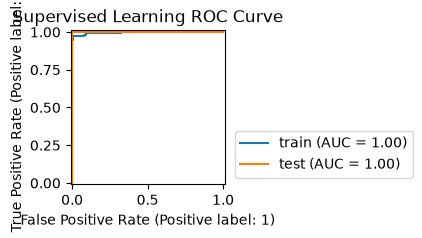

In [6]:
fig, ax = plt.subplots(figsize = (3, 2))
RocCurveDisplay.from_estimator(modelb, x_train, y_train, ax = ax, name = 'train')
RocCurveDisplay.from_estimator(modelb, x_test, y_test, ax = ax, name = 'test')
plt.title('Supervised Learning ROC Curve')
ax.legend(loc='lower left', bbox_to_anchor = (1.02, 0))
plt.show()

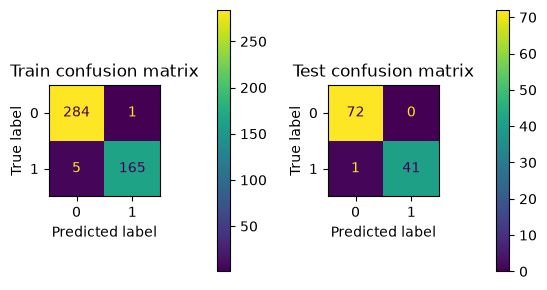

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(5, 3))
ConfusionMatrixDisplay.from_estimator(
    modelb, x_train, y_train, ax = ax[0])
ax[0].set_title('Train confusion matrix')
ConfusionMatrixDisplay.from_estimator(
    modelb, x_test, y_test, ax = ax[1]
)
ax[1].set_title('Test confusion matrix')
plt.tight_layout()
plt.subplots_adjust(wspace = 1)
for a in ax:
    cbar_ax = a.images[0].colorbar.ax
    pos = cbar_ax.get_position()
    cbar_ax.set_position([pos.x0 + 0.1, pos.y0, pos.width, pos.height])
plt.show()

#### (ii) Semi-Supervised Learning/ Self-training

##### (A)

In [8]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size = 0.2, stratify = y, random_state = 552)
x_labeled, x_unlabeled, y_labeled, _ = train_test_split(x_train, y_train,test_size = 0.5,stratify = y_train,random_state = 552)
print(y_labeled.value_counts())
print(x_unlabeled.shape)

1
0    142
1     85
Name: count, dtype: int64
(228, 30)


In [9]:
grid = GridSearchCV(pipeline, params, cv = 5)
grid.fit(x_labeled, y_labeled)
modelb = grid.best_estimator_
print(grid.best_params_)
print(grid.best_score_)

{'svm__C': np.float64(0.46415888336127775)}
0.9734299516908212


##### (B)

In [10]:
train_results = []
test_results = []
for i in range(30):
    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size = 0.2, stratify = y, random_state = i)
    x_labeled, x_unlabeled, y_labeled, _ = train_test_split(x_train, y_train,test_size = 0.5,stratify = y_train,random_state = i)
    grid = GridSearchCV(pipeline, params, cv = 5)
    grid.fit(x_labeled, y_labeled)
    modelb = grid.best_estimator_
    while len(x_unlabeled) > 0:
        distance = abs(modelb.decision_function(x_unlabeled))
        idx = np.argmax(distance)
        sample = x_unlabeled.iloc[[idx]]
        label = modelb.predict(sample)
        x_labeled = pd.concat([x_labeled, sample])
        y_labeled = pd.concat([
            y_labeled,
            pd.Series(label, index=sample.index)
        ])
        x_unlabeled = x_unlabeled.drop(sample.index)
        modelb.fit(x_labeled, y_labeled)
    for x_data, y_data, results in [
        (x_train, y_train, train_results),
        (x_test, y_test, test_results)
    ]:
        pred = modelb.predict(x_data)
        score = modelb.decision_function(x_data)
        results.append([
            accuracy_score(y_data, pred),
            precision_score(y_data, pred, zero_division=0),
            recall_score(y_data, pred),
            f1_score(y_data, pred),
            roc_auc_score(y_data, score)])
columns = ['accuracy', 'precision', 'recall', 'f1', 'auc']
print('train average:')
print(pd.DataFrame(train_results, columns=columns).mean())
print('\ntest average:')
print(pd.DataFrame(test_results, columns=columns).mean())

train average:
accuracy     0.978168
precision    0.980845
recall       0.960588
f1           0.970470
auc          0.994856
dtype: float64

test average:
accuracy     0.959942
precision    0.963483
recall       0.927778
f1           0.944629
auc          0.991634
dtype: float64


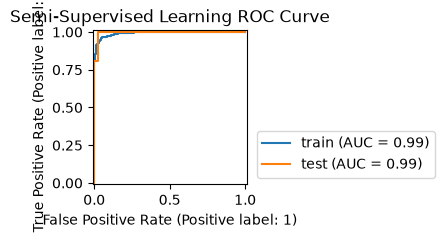

In [11]:
fig, ax = plt.subplots(figsize = (3, 2))
RocCurveDisplay.from_estimator(
    modelb, x_train, y_train, ax = ax, name = 'train')
RocCurveDisplay.from_estimator(
    modelb, x_test, y_test, ax = ax, name = 'test')
plt.title('Semi-Supervised Learning ROC Curve')
ax.legend(loc='lower left', bbox_to_anchor = (1.02, 0))
plt.show()

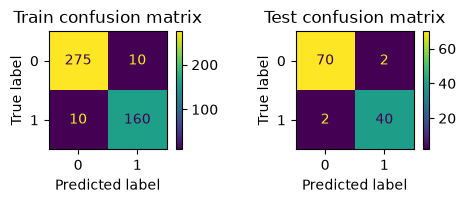

In [12]:
fig, ax = plt.subplots(1, 2, figsize = (5, 2))
ConfusionMatrixDisplay.from_estimator(
    modelb, x_train, y_train, ax = ax[0])
ax[0].set_title('Train confusion matrix')
ConfusionMatrixDisplay.from_estimator(
    modelb, x_test, y_test, ax=ax[1])
ax[1].set_title('Test confusion matrix')
plt.tight_layout()
plt.show()

#### (iii) Unsupervised Learning

##### (A)

In [13]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size = 0.2, stratify = y, random_state = 552)
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
kmeans = KMeans(
    n_clusters = 2,
    init = 'random',
    n_init = 20,
    random_state = 552)
clusters = kmeans.fit_predict(x_train_scaled)
print(np.bincount(clusters))
print('inertia:', kmeans.inertia_)

[159 296]
inertia: 9136.119846829251


To reduce the risk of getting trapped in a poor local minimum, K-means was run with 20 random initializations (n_init=20). The solution with the lowest inertia was selected.

##### (B)

In [14]:
train_results = []
test_results = []
for i in range(30):
    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size = 0.2, stratify = y, random_state = i )
    scaler = StandardScaler()
    x_train_scaled = scaler.fit_transform(x_train)
    x_test_scaled = scaler.transform(x_test)
    kmeans = KMeans(n_clusters = 2, init = 'random', n_init = 20, random_state = i)
    clusters = kmeans.fit_predict(x_train_scaled)
    cluster_labels = {}
    for j in range(2):
        distance = np.linalg.norm(
            x_train_scaled - kmeans.cluster_centers_[j], axis = 1)
        idx = np.where(clusters == j)[0]
        idx = idx[np.argsort(distance[idx])[:30]]
        cluster_labels[j] = y_train.iloc[idx].mode()[0]
    for x_data, y_data, results in [
        (x_train_scaled, y_train, train_results),
        (x_test_scaled, y_test, test_results)
    ]:
        cluster_pred = kmeans.predict(x_data)
        pred = np.array([cluster_labels[j] for j in cluster_pred])
        distance = kmeans.transform(x_data)
        if cluster_labels[0] != cluster_labels[1]:
            positive_cluster = [j for j in range(2) if cluster_labels[j] == 1][0]
            negative_cluster = [j for j in range(2) if cluster_labels[j] == 0][0]
            score = distance[:, negative_cluster] - distance[:, positive_cluster]
        else:
            score = np.full(len(x_data), cluster_labels[0])
        results.append([
            accuracy_score(y_data, pred),
            precision_score(y_data, pred, zero_division=0),
            recall_score(y_data, pred),
            f1_score(y_data, pred),
            roc_auc_score(y_data, score)])
columns = ['accuracy', 'precision', 'recall', 'f1', 'auc']
print('train average:')
print(pd.DataFrame(train_results, columns=columns).mean())

train average:
accuracy     0.910256
precision    0.923860
recall       0.828431
f1           0.873355
auc          0.974868
dtype: float64


##### (C)

In [15]:
print('test average:')
print(pd.DataFrame(test_results, columns=columns).mean())

test average:
accuracy     0.905263
precision    0.909638
recall       0.826190
f1           0.864657
auc          0.971869
dtype: float64


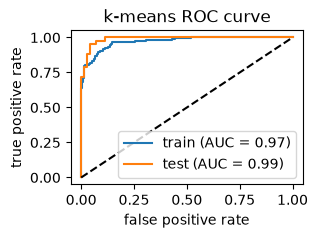

In [16]:
fig, ax = plt.subplots(figsize=(3, 2))
for name, x_data, y_data in [
    ('train', x_train_scaled, y_train),
    ('test', x_test_scaled, y_test)
]:
    distance = kmeans.transform(x_data)
    if cluster_labels[0] != cluster_labels[1]:
        positive_cluster = [j for j in range(2) if cluster_labels[j] == 1][0]
        negative_cluster = [j for j in range(2) if cluster_labels[j] == 0][0]
        score = distance[:, negative_cluster] - distance[:, positive_cluster]
    else:
        score = np.full(len(x_data), cluster_labels[0])
    fpr, tpr, _ = roc_curve(y_data, score)
    auc = roc_auc_score(y_data, score)
    ax.plot(fpr, tpr, label = f'{name} (AUC = {auc:.2f})')
ax.plot([0, 1], [0, 1], 'k--')
ax.set_xlabel('false positive rate')
ax.set_ylabel('true positive rate')
ax.set_title('k-means ROC curve')
ax.legend()
plt.show()

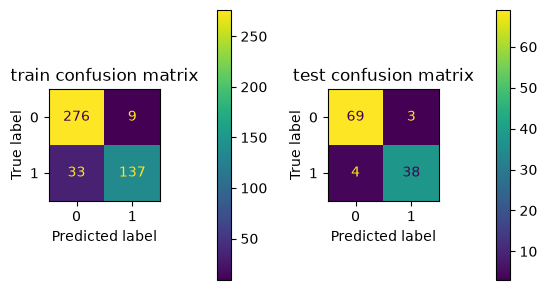

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(5, 3))
for i, (name, x_data, y_data) in enumerate([
    ('train', x_train_scaled, y_train),
    ('test', x_test_scaled, y_test)
]):
    clusters = kmeans.predict(x_data)
    pred = np.array([cluster_labels[j] for j in clusters])
    ConfusionMatrixDisplay.from_predictions(
        y_data, pred, ax = ax[i])
    ax[i].set_title(f'{name} confusion matrix')
plt.tight_layout()
plt.subplots_adjust(wspace = 1)
for a in ax:
    cbar_ax = a.images[0].colorbar.ax
    pos = cbar_ax.get_position()
    cbar_ax.set_position([pos.x0 + 0.1, pos.y0, pos.width, pos.height])
plt.show()

#### (iv) Spectral Clustering

Spectral clustering is an unsupervised learning method that groups data points based on their similarity. It constructs a similarity matrix, uses the graph Laplacian and its eigenvectors to transform the data into a lower-dimensional space, and then applies clustering. Unlike k-means, spectral clustering can identify non-convex clusters.

Reference: https://www.geeksforgeeks.org/machine-learning/spectral-clustering/

In [18]:
train_results = []
test_results = []
for i in range(30):
    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size = 0.2, stratify = y, random_state = i)
    scaler = StandardScaler()
    x_train_scaled = scaler.fit_transform(x_train)
    x_test_scaled = scaler.transform(x_test)
    x_all = np.vstack([x_train_scaled, x_test_scaled])
    spectral = SpectralClustering(
        n_clusters = 2,
        affinity = 'rbf',
        gamma = 1,
        assign_labels = 'kmeans',
        random_state = i)
    clusters = spectral.fit_predict(x_all)
    train_clusters = clusters[:len(x_train)]
    test_clusters = clusters[len(x_train):]
    cluster_labels = {}
    for j in range(2):
        idx = np.where(train_clusters == j)[0]
        selected = np.random.default_rng(i + j).choice(
            idx, size=min(30, len(idx)), replace=False)
        cluster_labels[j] = y_train.iloc[selected].mode()[0]
    for cluster_pred, y_data, results in [
        (train_clusters, y_train, train_results),
        (test_clusters, y_test, test_results)
    ]:
        pred = np.array([cluster_labels[j] for j in cluster_pred])
        score = pred.astype(float)
        results.append([
            accuracy_score(y_data, pred),
            precision_score(y_data, pred, zero_division=0),
            recall_score(y_data, pred),
            f1_score(y_data, pred),
            roc_auc_score(y_data, score)])
columns = ['accuracy', 'precision', 'recall', 'f1', 'auc']
print('train average:')
print(pd.DataFrame(train_results, columns=columns).mean())
print('\ntest average:')
print(pd.DataFrame(test_results, columns=columns).mean())

train average:
accuracy     0.629963
precision    1.000000
recall       0.009608
f1           0.019017
auc          0.504804
dtype: float64

test average:
accuracy     0.634795
precision    0.366667
recall       0.008730
f1           0.017054
auc          0.504365
dtype: float64


I initially used gamma = 1, but almost all observations were assigned to one cluster. Therefore, I tested smaller gamma values to obtain a more balanced result.

In [19]:
gammas = [0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1]
for gamma in gammas:
    spectral = SpectralClustering(
        n_clusters = 2,affinity = 'rbf',gamma = gamma,assign_labels = 'kmeans',random_state = 552)
    clusters = spectral.fit_predict(x_train_scaled)
    print('gamma:', gamma, 'cluster sizes:', np.bincount(clusters))

gamma: 0.001 cluster sizes: [308 147]
gamma: 0.005 cluster sizes: [332 123]
gamma: 0.01 cluster sizes: [347 108]
gamma: 0.05 cluster sizes: [ 90 365]
gamma: 0.1 cluster sizes: [365  90]
gamma: 0.5 cluster sizes: [450   5]
gamma: 1 cluster sizes: [454   1]


I tested several gamma values from 0.001 to 1. Among them, gamma = 0.001 produced cluster sizes of 308 and 147, which were the closest to the original class distribution of 285 and 170.

In [20]:
gammas = [0.00001, 0.00005, 0.0001, 0.0002, 0.0005, 0.001]
for gamma in gammas:
    spectral = SpectralClustering(n_clusters = 2,affinity = 'rbf',gamma = gamma,assign_labels = 'kmeans',random_state = 552)
    clusters = spectral.fit_predict(x_train_scaled)
    print('gamma:', gamma, 'cluster sizes:', np.bincount(clusters))

gamma: 1e-05 cluster sizes: [306 149]
gamma: 5e-05 cluster sizes: [148 307]
gamma: 0.0001 cluster sizes: [147 308]
gamma: 0.0002 cluster sizes: [147 308]
gamma: 0.0005 cluster sizes: [147 308]
gamma: 0.001 cluster sizes: [308 147]


I further tested smaller gamma values, but none produced a better balance. Therefore, I selected gamma = 0.001 for the final Monte Carlo simulation, although the cluster sizes did not exactly match the original class distribution.

In [21]:
train_results = []
test_results = []
for i in range(30):
    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size = 0.2, stratify = y, random_state = i)
    scaler = StandardScaler()
    x_train_scaled = scaler.fit_transform(x_train)
    x_test_scaled = scaler.transform(x_test)
    x_all = np.vstack([x_train_scaled, x_test_scaled])
    spectral = SpectralClustering(
        n_clusters = 2,
        affinity = 'rbf',
        gamma = 0.001,
        assign_labels = 'kmeans',
        random_state = i)
    clusters = spectral.fit_predict(x_all)
    train_clusters = clusters[:len(x_train)]
    test_clusters = clusters[len(x_train):]
    cluster_labels = {}
    for j in range(2):
        idx = np.where(train_clusters == j)[0]

        selected = np.random.default_rng(i + j).choice(
            idx, size=min(30, len(idx)), replace=False)
        cluster_labels[j] = y_train.iloc[selected].mode()[0]
    cluster_scores = {}
    for j in range(2):
        idx = np.where(train_clusters == j)[0]
        cluster_scores[j] = y_train.iloc[idx].mean()
    for cluster_pred, y_data, results in [
        (train_clusters, y_train, train_results),
        (test_clusters, y_test, test_results)
    ]:
        pred = np.array([cluster_labels[j] for j in cluster_pred])
        score = np.array([cluster_scores[j] for j in cluster_pred])
        results.append([
            accuracy_score(y_data, pred),
            precision_score(y_data, pred, zero_division=0),
            recall_score(y_data, pred),
            f1_score(y_data, pred),
            roc_auc_score(y_data, score)])
columns = ['accuracy', 'precision', 'recall', 'f1', 'auc']
print('train average:')
print(pd.DataFrame(train_results, columns=columns).mean())
print('\ntest average:')
print(pd.DataFrame(test_results, columns=columns).mean())

train average:
accuracy     0.910110
precision    0.929139
recall       0.822353
f1           0.872344
auc          0.892405
dtype: float64

test average:
accuracy     0.907310
precision    0.919477
recall       0.822222
f1           0.866783
auc          0.889583
dtype: float64


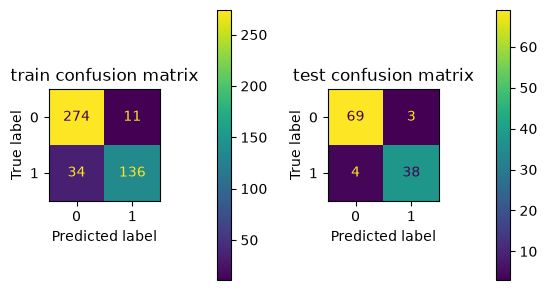

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(5, 3))
for j, (name, cluster_pred, y_data) in enumerate([
    ('train', train_clusters, y_train),
    ('test', test_clusters, y_test)
]):
    pred = np.array([cluster_labels[k] for k in cluster_pred])
    ConfusionMatrixDisplay.from_predictions(
        y_data, pred, ax = ax[j])
    ax[j].set_title(f'{name} confusion matrix')
plt.tight_layout()
plt.subplots_adjust(wspace = 1)
for a in ax:
    cbar_ax = a.images[0].colorbar.ax
    pos = cbar_ax.get_position()
    cbar_ax.set_position([pos.x0 + 0.1, pos.y0, pos.width, pos.height])
plt.show()

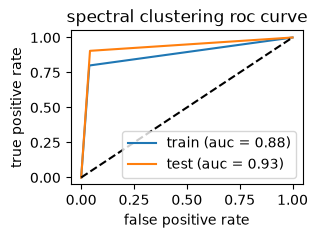

In [23]:
cluster_scores = {}
for j in range(2):
    idx = np.where(train_clusters == j)[0]
    cluster_scores[j] = y_train.iloc[idx].mean()
fig, ax = plt.subplots(figsize=(3, 2))
for name, cluster_pred, y_data in [
    ('train', train_clusters, y_train),
    ('test', test_clusters, y_test)
]:
    score = np.array([cluster_scores[j] for j in cluster_pred])
    fpr, tpr, _ = roc_curve(y_data, score)
    auc = roc_auc_score(y_data, score)
    ax.plot(fpr, tpr, label=f'{name} (auc = {auc:.2f})')
ax.plot([0, 1], [0, 1], 'k--')
ax.set_xlabel('false positive rate')
ax.set_ylabel('true positive rate')
ax.set_title('spectral clustering roc curve')
ax.legend()
plt.show()

#### (v) Compare

Supervised learning achieved the best overall performance, with the highest test accuracy (96.73%), F1-score (95.48%), and AUC (99.26%). Semi-supervised learning performed slightly worse but still achieved strong results using only half of the training labels initially.

Both unsupervised methods performed worse than the supervised methods, especially in recall. Supervised and semi-supervised learning achieved test recall rates of 93.97% and 92.70%, while k-means and spectral clustering achieved 82.62% and 82.22%, respectively. K-means and spectral clustering had similar test accuracy, around 90.5%–90.7%.

Overall, the results suggest that using labeled data improves classification performance. However, the AUC values of the two clustering methods are not directly comparable because different scoring approaches were used. Spectral clustering also included test features during clustering, unlike the other methods.

## 2. Active Learning Using Support Vector Machines

### (a) Download the banknote authentication Data Set

In [24]:
banknote = pd.read_csv('../data/data_banknote_authentication.txt', header=None)

x = banknote.iloc[:, :4]
y = banknote.iloc[:, 4]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size = 472, random_state = 552
)

print(banknote.shape)
print(x_train.shape)
print(x_test.shape)
print(y_train.value_counts())
print(y_test.value_counts())

(1372, 5)
(900, 4)
(472, 4)
4
0    512
1    388
Name: count, dtype: int64
4
0    250
1    222
Name: count, dtype: int64


### (b) Repeat each of the following two procedures 50 times

#### (i) Passive

In [25]:
pipeline2 = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', LinearSVC(
        penalty = 'l1',
        dual = False,
        max_iter = 100000,
        tol = 1e-3
    ))
])

In [26]:
passive_errors = []

for i in range(50):
    rng = np.random.default_rng(i)

    while True:
        order = rng.permutation(len(x_train))
        first_y = y_train.iloc[order[:10]]

        if first_y.nunique() == 2 and first_y.value_counts().min() >= 5:
            break

    errors = []

    for n in range(10, 901, 10):
        idx = order[:n]

        x_pool = x_train.iloc[idx]
        y_pool = y_train.iloc[idx]

        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=i)

        grid = GridSearchCV(pipeline2, params, cv=cv)
        grid.fit(x_pool, y_pool)

        pred = grid.best_estimator_.predict(x_test)
        errors.append(1 - accuracy_score(y_test, pred))

    passive_errors.append(errors)

print(np.array(passive_errors).shape)

(50, 90)


#### (ii) Active

In [27]:
active_errors = []

for i in range(50):
    rng = np.random.default_rng(i)

    while True:
        order = rng.permutation(len(x_train))
        first_y = y_train.iloc[order[:10]]

        if first_y.nunique() == 2 and first_y.value_counts().min() >= 5:
            break

    selected = list(order[:10])
    remaining = list(order[10:])
    errors = []

    for n in range(10, 901, 10):
        x_pool = x_train.iloc[selected]
        y_pool = y_train.iloc[selected]

        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=i)

        grid = GridSearchCV(pipeline2, params, cv=cv)
        grid.fit(x_pool, y_pool)

        model = grid.best_estimator_

        pred = model.predict(x_test)
        errors.append(1 - accuracy_score(y_test, pred))

        if n < 900:
            distance = abs(
                model.decision_function(x_train.iloc[remaining])
            )

            idx = np.argsort(distance)[:10]
            new_samples = [remaining[j] for j in idx]

            selected.extend(new_samples)
            remaining = [j for j in remaining if j not in new_samples]

    active_errors.append(errors)

print(np.array(active_errors).shape)

(50, 90)


### (c) Average the 50 test errors

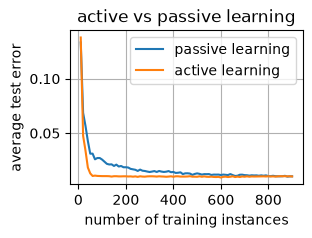

In [28]:
passive_mean = np.mean(passive_errors, axis = 0)
active_mean = np.mean(active_errors, axis = 0)

n = np.arange(10, 901, 10)

plt.figure(figsize = (3, 2))

plt.plot(n, passive_mean, label = 'passive learning')
plt.plot(n, active_mean, label = 'active learning')

plt.xlabel('number of training instances')
plt.ylabel('average test error')
plt.title('active vs passive learning')
plt.legend()
plt.grid(True)
plt.show()

When the number of training instances increases from 10 to 200, the test errors of both methods decrease rapidly. However, active learning decreases faster and achieves a lower test error with fewer training instances.

Between 200 and 500 training instances, the two curves become closer. Active learning occasionally has a slightly higher test error than passive learning, indicating that it does not always perform better.

From 500 to 900 training instances, both methods stabilize at approximately 1% test error, and their curves become nearly identical. This is because both methods eventually use all 900 training instances.

Overall, active learning is more effective when the number of labeled training instances is limited, while the difference between the two methods becomes smaller as the training set increases.